# Neural v2 Decipherment: Classical Ge'ez (Ethiopic)

## Hypothesis

The Voynich Manuscript's 166 distinct glyphs have always been the central puzzle: too many
for an alphabet (~26), too few for logographic writing (~1000+). Every language tested so far
(Hebrew, Arabic, Aramaic, Judeo-Arabic) uses ~22-27 characters, giving a ratio |sigma|/|A| ~ 6-7.
This forces the optimizer into massive many-to-one collapse where the language model dominates
and all discriminative power is lost.

**Classical Ge'ez (Ethiopic) is the first language where this ratio approaches 1:1.**

Ge'ez has **188 syllable characters** (fidel) vs the Voynich's **166 glyphs**, giving
|sigma|/|A| = 166/188 ~ 0.88. Each Ge'ez character encodes a full CV syllable (consonant + vowel),
which is exactly what the SilPart model predicts: Voynich glyphs behave as positional syllable
units, not individual phonemes.

## Historical plausibility

Ethiopian Christian delegations visited Rome and Florence repeatedly in the 15th century.
The Council of Florence (1441) included Ethiopian representatives. Pietro della Valle and
other Italian scholars acquired Ethiopic manuscripts. A Ge'ez-speaking community existed in
Rome by the late 15th century. The timeline overlaps with Voynich dating (1404-1438).

## Key difference from all previous tests

- **Previous tests**: 166 glyphs -> 22-27 chars (ratio 6-7x), LM dominance collapse inevitable
- **This test**: 166 glyphs -> 188 syllables (ratio 0.88), near-injective mapping possible
- **No C/V constraint**: Every Ge'ez char is a syllable (role='S'), so all roles set to 'C'
  to make the constraint inactive. The optimizer can map any glyph to any Ge'ez syllable.
- **No grammar anchors**: Hebrew morphological anchors (prefix/suffix) do not apply to Ge'ez.
- **No root matching**: Ge'ez uses a different root system; Hebrew roots are not applicable.


In [1]:
# -- Cell 1: Imports ----------------------------------------------------------
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cpu
Imports OK


In [2]:
# -- Cell 2: Load Voynich corpus ----------------------------------------------
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# -- Segmentation and positional classification --

def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# -- Load and process Voynich --
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role_original, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

# For Ge'ez: override ALL glyph roles to 'C' (no C/V distinction needed)
# This makes the C/V constraint inactive -- any glyph can map to any Ge'ez syllable
glyph_role = {g: 'C' for g in VOCAB}

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')
print(f'Classification (overridden for Ge\'ez): C={n_c}, V={n_v}, ?={n_q}')
print(f'(Original classification was C={sum(1 for g in VOCAB if glyph_role_original[g]=="C")}, '
      f'V={sum(1 for g in VOCAB if glyph_role_original[g]=="V")}, '
      f'?={sum(1 for g in VOCAB if glyph_role_original[g]=="?")})')

Voynich: 37,087 words, 157,254 tokens, 166 glyphs
Classification (overridden for Ge'ez): C=166, V=0, ?=0
(Original classification was C=70, V=5, ?=91)


In [3]:
# -- Cell 3: Load Ge'ez corpus + CharLM baseline (no grammar anchors) --------

import json as json_mod

with open('corpus/geez_processed.json') as f:
    geez_corpus = json_mod.load(f)

hebrew_words_full = [list(w) for w in geez_corpus['words_full']]  # 62,671 words (alias for compatibility)
hebrew_words = hebrew_words_full  # alias: full corpus used everywhere
hebrew_words_sub = [list(w) for w in geez_corpus['words']]        # 37,087 subsampled
char_role_geez = geez_corpus.get('char_role', {})

# All Ge'ez chars are syllables -> set role 'C' for all (makes C/V constraint inactive)
target_chars_heb = sorted(char_role_geez.keys())
char_role_heb = {c: 'C' for c in target_chars_heb}  # override: all 'C'

print(f'Ge\'ez (Ethiopic) corpus:')
print(f'  Full: {len(hebrew_words_full):,} words')
print(f'  Subsampled: {len(hebrew_words_sub):,} words')
print(f'  Syllable chars: {len(target_chars_heb)}')
print(f'  |sigma|/|A| ratio: {len(VOCAB)}/{len(target_chars_heb)} = {len(VOCAB)/len(target_chars_heb):.2f}')
print(f'  Mean word length (full): {np.mean([len(w) for w in hebrew_words_full]):.2f} syllables')
print(f'  Mean word length (sub): {np.mean([len(w) for w in hebrew_words_sub]):.2f} syllables')
print(f'  All roles set to C (no C/V distinction)')

# CharLM trigram baseline
class CharLM:
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS, EOS = '<w>', '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri = self.trigram_counts[ctx]
        tri_total = sum(tri.values())
        if tri_total > 0:
            tri_seen = len(tri)
            count = tri.get(c3, 0)
            if count > 0:
                return math.log2(max(count / (tri_total + tri_seen), 1e-20))
            else:
                lb = tri_seen / (tri_total + tri_seen)
                bi = self.bigram_counts[c2]
                bi_total = sum(bi.values())
                if bi_total > 0:
                    bi_seen = len(bi)
                    bi_count = bi.get(c3, 0)
                    if bi_count > 0:
                        return math.log2(max(lb * bi_count / (bi_total + bi_seen), 1e-20))
                    else:
                        lb2 = bi_seen / (bi_total + bi_seen)
                        return math.log2(max(lb * lb2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V), 1e-20))
                else:
                    return math.log2(max(lb * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V), 1e-20))
        else:
            bi = self.bigram_counts[c2]
            bi_total = sum(bi.values())
            if bi_total > 0:
                bi_seen = len(bi)
                count = bi.get(c3, 0)
                if count > 0:
                    return math.log2(max(count / (bi_total + bi_seen), 1e-20))
                else:
                    lb = bi_seen / (bi_total + bi_seen)
                    return math.log2(max(lb * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V), 1e-20))
            else:
                return math.log2(max((self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V), 1e-20))

    def log_prob(self, word):
        BOS, EOS = '<w>', '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        return sum(self._log_prob_trigram(seq[i-2], seq[i-1], seq[i]) for i in range(2, len(seq)))

    def perplexity(self, words):
        total_lp = sum(self.log_prob(w) for w in words)
        total_n = sum(len(w) + 1 for w in words)
        return 2.0 ** (-total_lp / total_n) if total_n > 0 else float('inf')

char_lm_baseline = CharLM(order=3)
char_lm_baseline.fit(hebrew_words_full)
ppx_baseline = char_lm_baseline.perplexity(hebrew_words_sub[:5000])
print(f'\nCharLM baseline PPX: {ppx_baseline:.2f}')

# No grammar anchors for Ge'ez (Hebrew morphological anchors don't apply)
glyph_anchor_sets = {}
print(f'Grammar anchors: {len(glyph_anchor_sets)} (none -- Ge\'ez has no Hebrew-style prefix/suffix system)')

Ge'ez (Ethiopic) corpus:
  Full: 62,671 words
  Subsampled: 37,087 words
  Syllable chars: 188
  |sigma|/|A| ratio: 166/188 = 0.88
  Mean word length (full): 3.64 syllables
  Mean word length (sub): 3.64 syllables
  All roles set to C (no C/V distinction)

CharLM baseline PPX: 8.52
Grammar anchors: 0 (none -- Ge'ez has no Hebrew-style prefix/suffix system)


In [4]:
# -- Cell 4: NeuralCharLM -- LSTM architecture --------------------------------

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# -- Build vocabulary from FULL corpus (for LM training) --
all_chars_heb = sorted(set(c for w in hebrew_words_full for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} Ge\'ez syllables + {len(special_tokens)} special)')
n_params = sum(p.numel() for p in NeuralCharLM(len(char_vocab)).parameters())
print(f'Parameters: {n_params:,}')

Neural LM vocab: 192 tokens (188 Ge'ez syllables + 4 special)
Parameters: 513,216


Train: 50,137 words, Val: 12,534 words
Train samples: 232,503, Val samples: 58,091

Training Neural LM on FULL Ge'ez corpus (30 epochs, patience=5)...
  Epoch  1: train_loss=3.1111, val_loss=2.5374, lr=0.001995
  Epoch  5: train_loss=2.2578, val_loss=2.1388, lr=0.001866
  Epoch 10: train_loss=2.1620, val_loss=2.0762, lr=0.001500
  Epoch 15: train_loss=2.1149, val_loss=2.0449, lr=0.001000
  Epoch 20: train_loss=2.0845, val_loss=2.0264, lr=0.000500
  Epoch 25: train_loss=2.0684, val_loss=2.0188, lr=0.000134
  Epoch 30: train_loss=2.0614, val_loss=2.0165, lr=0.000000

Training completed in 137.7s

Perplexity on validation (2000 words):
  CharLM trigram (baseline): 8.19
  NeuralCharLM (T=1.0):     9.97


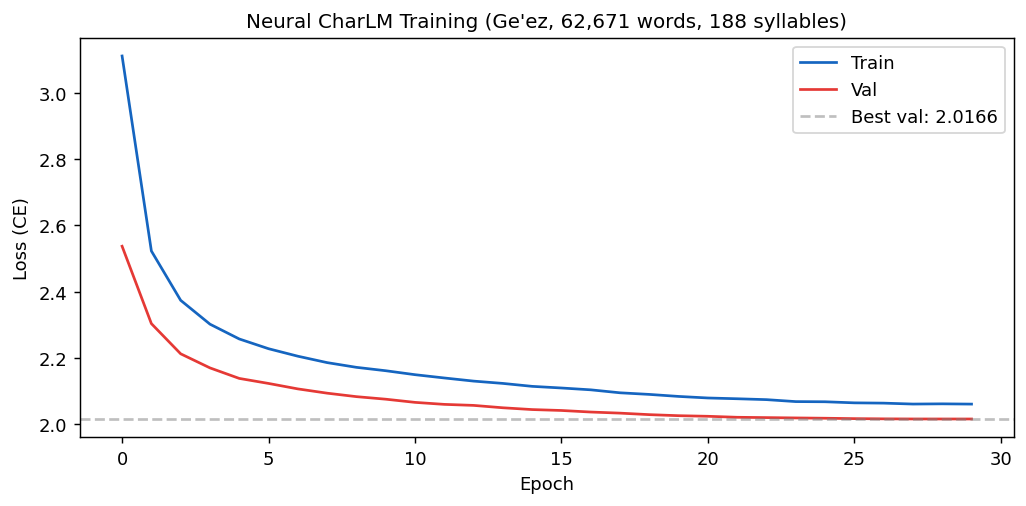

In [5]:
# -- Cell 5: Neural LM training (on FULL 62K Ge'ez corpus) --------------------

# Train/val split on the FULL corpus
rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words_full))
perm = rng_split.permutation(len(hebrew_words_full))
val_idx = set(perm[:n_val])
train_words = [hebrew_words_full[i] for i in range(len(hebrew_words_full)) if i not in val_idx]
val_words = [hebrew_words_full[i] for i in range(len(hebrew_words_full)) if i in val_idx]
print(f'Train: {len(train_words):,} words, Val: {len(val_words):,} words')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f'Train samples: {len(train_dataset):,}, Val samples: {len(val_dataset):,}')

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses = []
val_losses = []

print(f'\nTraining Neural LM on FULL Ge\'ez corpus ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss = 0.0
    n_batches = 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    val_loss = 0.0
    n_val_batches = 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'lr={scheduler.get_last_lr()[0]:.6f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining completed in {elapsed:.1f}s')

neural_lm.load_state_dict(best_state_dict)

neural_val_ppx = neural_lm.perplexity(val_words[:2000], temperature=1.0)
baseline_val_ppx = char_lm_baseline.perplexity(val_words[:2000])
print(f'\nPerplexity on validation (2000 words):')
print(f'  CharLM trigram (baseline): {baseline_val_ppx:.2f}')
print(f'  NeuralCharLM (T=1.0):     {neural_val_ppx:.2f}')

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, linestyle='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CE)')
ax.set_title(f'Neural CharLM Training (Ge\'ez, {len(hebrew_words_full):,} words, {len(all_chars_heb)} syllables)')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# -- Cell 6: GlyphMappingState + Scoring (no root helpers for Ge'ez) ----------

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def propose_change_tracked(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


# -- Scoring functions --

def score_positional(mapping, glyph_role, char_role):
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_grammar(mapping_state, glyph_anchor_sets):
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        if mapping_state.mapping.get(g) in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_total_neural(mapping_state, words_sample, neural_lm, temperature,
                       glyph_role, char_role, glyph_anchor_sets,
                       w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                       w_gram=0.0, K_max=23):
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_pos = score_positional(mapping_state, glyph_role, char_role)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    s_gram = score_grammar(mapping_state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm,
                            temperature, glyph_role, char_role, glyph_anchor_sets,
                            glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                            w_gram=0.0, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional(proposal, glyph_role, char_role)
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    s_gram = score_grammar(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps


# -- Hard-K proposal --
def propose_change_hard_k(state, rng, K_min=20, constrained=True, max_retries=50):
    for _ in range(max_retries):
        new, glyph = state.propose_change_tracked(rng, constrained)
        if len(set(new.mapping.values())) >= K_min:
            return new, glyph
    return None, None


print('Scoring functions loaded (w_gram=0.0 default for Ge\'ez)')
print(f'Note: No Hebrew root matching -- Ge\'ez uses a different root system')

Scoring functions loaded (w_gram=0.0 default for Ge'ez)
Note: No Hebrew root matching -- Ge'ez uses a different root system


In [7]:
# -- Cell 7: Strategy A -- Multi-Seed EM (T=3, parallel) ----------------------
import os, contextlib, io
os.environ['CUDA_VISIBLE_DEVICES'] = ''
from multiprocessing import Pool, cpu_count
import torch

# Force single-threaded torch in workers to avoid deadlock
torch.set_num_threads(1)
neural_lm.eval()

N_SEEDS = 20
T_FIXED = 3.0
# w_gram=0.0: no grammar anchors for Ge'ez
# K_max adjusted for 188 target chars (higher cardinality expected)
SCORE_KW = dict(w_gram=0.0, w_card=0.5, K_max=100)
SAMPLE_EM = 3000
EM_ITERS = 2000
EM_PATIENCE = 100
PROPOSALS_PER_ITER = 200
N_CPUS = max(1, cpu_count() - 1)

# Prepare EM sample
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)

# Base frequency mapping
base_mapping = init_frequency_mapping(
    palabras, VOCAB, target_chars_heb, hebrew_words_full,
    glyph_role, char_role_heb)

def _em_seed_worker(seed_idx):
    torch.set_num_threads(1)
    rng = np.random.default_rng(42 + seed_idx * 137)
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    if seed_idx < 10:
        mapping_init = dict(base_mapping)
        glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
        for g in glyphs_to_scramble:
            # All roles are 'C', so candidates = all target chars (unconstrained)
            mapping_init[g] = rng.choice(target_chars_heb)
        state.set_mapping(mapping_init)
    else:
        mapping_init = {}
        for g in VOCAB:
            mapping_init[g] = rng.choice(target_chars_heb)
        state.set_mapping(mapping_init)

    with torch.no_grad():
        best_score, best_word_lps = score_total_neural(
            state, words_em, neural_lm, T_FIXED,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)
        best_state = state
        no_improve = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                proposal, changed_glyph = best_state.propose_change_tracked(rng, constrained=True)
                prop_score, prop_word_lps = score_total_incremental(
                    proposal, changed_glyph, words_em, neural_lm, T_FIXED,
                    glyph_role, char_role_heb, glyph_anchor_sets,
                    glyph_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True
            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

    elapsed = time.time() - t0
    K_eff = len(set(best_state.mapping.values()))

    return {
        'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'grammar': 0.0,  # no grammar anchors
        'n_roots': 0,    # no root matching for Ge'ez
        'roots': set(),
        'n_matches': 0,
        'elapsed': elapsed,
        'mapping': dict(best_state.mapping),
        'word_lps': list(best_word_lps) if best_word_lps is not None else None,
        'iter_converged': it + 1,
    }

print(f'Strategy A: {N_SEEDS} seeds, T={T_FIXED}, {SAMPLE_EM} words, {EM_ITERS} iter')
print(f'Target alphabet: {len(target_chars_heb)} Ge\'ez syllables (unconstrained proposals)')
print(f'Running on {N_CPUS} CPUs...')
t0_total = time.time()
with Pool(N_CPUS) as pool:
    raw_results_a = pool.map(_em_seed_worker, range(N_SEEDS))

# Reconstruct full result objects with GlyphMappingState
multi_seed_results = []
for r in raw_results_a:
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(r['mapping'])
    r['state'] = state
    if r['word_lps'] is not None:
        r['word_lps'] = np.array(r['word_lps'])
    multi_seed_results.append(r)

elapsed_total = time.time() - t0_total
print(f'Total wall time: {elapsed_total:.0f}s')

for r in multi_seed_results:
    init_type = 'freq+scramble' if r['seed'] < 10 else 'random'
    print(f'  Seed {r["seed"]:2d} [{init_type:13s}]: score={r["score"]:.4f}, K={r["K_eff"]:3d}, '
          f'iter={r["iter_converged"]}, {r["elapsed"]:.0f}s')

# Summary
print(f'\n{"="*60}')
print('Strategy A -- Summary')
print(f'{"="*60}')
df_a = pd.DataFrame([{
    'Seed': r['seed'], 'Init': 'freq' if r['seed'] < 10 else 'rand',
    'Score': f"{r['score']:.4f}", 'K_eff': r['K_eff'],
    'Iter': r['iter_converged'], 'Time': f"{r['elapsed']:.0f}s"
} for r in multi_seed_results])
print(df_a.to_string(index=False))

scores_a = [r['score'] for r in multi_seed_results]
print(f'\nScore: mean={np.mean(scores_a):.4f}, std={np.std(scores_a):.4f}')
keffs_a = [r['K_eff'] for r in multi_seed_results]
print(f'K_eff: mean={np.mean(keffs_a):.1f}, std={np.std(keffs_a):.1f}, '
      f'min={min(keffs_a)}, max={max(keffs_a)}')

Strategy A: 20 seeds, T=3.0, 3000 words, 2000 iter
Target alphabet: 188 Ge'ez syllables (unconstrained proposals)
Running on 15 CPUs...
Total wall time: 5168s
  Seed  0 [freq+scramble]: score=-51.1879, K=122, iter=1271, 4065s
  Seed  1 [freq+scramble]: score=-47.2303, K=114, iter=1097, 3628s
  Seed  2 [freq+scramble]: score=-52.8912, K=121, iter=1273, 4099s
  Seed  3 [freq+scramble]: score=-52.5527, K=119, iter=719, 2377s
  Seed  4 [freq+scramble]: score=-51.4048, K=120, iter=1179, 3858s
  Seed  5 [freq+scramble]: score=-47.2472, K=109, iter=1492, 4378s
  Seed  6 [freq+scramble]: score=-49.1260, K=123, iter=1493, 4372s
  Seed  7 [freq+scramble]: score=-52.4074, K=124, iter=886, 2892s
  Seed  8 [freq+scramble]: score=-52.3113, K=119, iter=582, 1883s
  Seed  9 [freq+scramble]: score=-51.8841, K=124, iter=1377, 4258s
  Seed 10 [random       ]: score=-53.5471, K=128, iter=927, 3032s
  Seed 11 [random       ]: score=-53.7177, K=100, iter=1147, 3810s
  Seed 12 [random       ]: score=-51.8327

In [8]:
# -- Cell 8: Strategy B -- Hard-K + Low T (parallel) --------------------------
T_VALUES_LOW = [1.5, 2.0]
K_MIN = 100  # Adjusted for 188 target chars
N_SEEDS_B = 5

configs_b = [(T_low, seed_idx) for T_low in T_VALUES_LOW for seed_idx in range(N_SEEDS_B)]

def _hard_k_worker(args):
    T_low, seed_idx = args
    torch.set_num_threads(1)
    rng = np.random.default_rng(1000 + seed_idx * 137 + int(T_low * 100))

    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    mapping_init = dict(base_mapping)
    glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
    for g in glyphs_to_scramble:
        mapping_init[g] = rng.choice(target_chars_heb)
    state.set_mapping(mapping_init)

    with torch.no_grad():
        best_score, best_word_lps = score_total_neural(
            state, words_em, neural_lm, T_low,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)
        best_state = state
        no_improve = 0
        n_rejections = 0
        n_proposals_total = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                n_proposals_total += 1
                proposal, changed_glyph = propose_change_hard_k(
                    best_state, rng, K_min=K_MIN, constrained=True)
                if proposal is None:
                    n_rejections += 1
                    continue
                prop_score, prop_word_lps = score_total_incremental(
                    proposal, changed_glyph, words_em, neural_lm, T_low,
                    glyph_role, char_role_heb, glyph_anchor_sets,
                    glyph_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True
            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

    elapsed = time.time() - t0
    K_eff = len(set(best_state.mapping.values()))
    reject_pct = n_rejections / max(n_proposals_total, 1)

    return {
        'T': T_low, 'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'grammar': 0.0, 'n_roots': 0, 'roots': set(),
        'n_matches': 0, 'elapsed': elapsed,
        'mapping': dict(best_state.mapping),
        'word_lps': list(best_word_lps) if best_word_lps is not None else None,
        'n_rejections': n_rejections, 'reject_pct': reject_pct,
        'iter_converged': it + 1,
    }

print(f'Strategy B: Hard-K (K_min={K_MIN}), T={T_VALUES_LOW}, {N_SEEDS_B} seeds per T')
print(f'Running {len(configs_b)} configs on {N_CPUS} CPUs...')
t0_total = time.time()
with Pool(N_CPUS) as pool:
    raw_results_b = pool.map(_hard_k_worker, configs_b)

hard_k_results = []
for r in raw_results_b:
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(r['mapping'])
    r['state'] = state
    if r['word_lps'] is not None:
        r['word_lps'] = np.array(r['word_lps'])
    hard_k_results.append(r)

elapsed_total = time.time() - t0_total
print(f'Total wall time: {elapsed_total:.0f}s')

for r in hard_k_results:
    print(f'  T={r["T"]}, Seed {r["seed"]}: score={r["score"]:.4f}, K={r["K_eff"]:3d}, '
          f'reject={r["reject_pct"]:.1%}, {r["elapsed"]:.0f}s')

# Summary
print(f'\n{"="*60}')
print('Strategy B -- Summary')
print(f'{"="*60}')
rows_b = []
for r in hard_k_results:
    rows_b.append({
        'T': r['T'], 'Seed': r['seed'],
        'Score': f"{r['score']:.4f}", 'K_eff': r['K_eff'],
        'Reject%': f"{r['reject_pct']:.1%}",
        'Iter': r['iter_converged'], 'Time': f"{r['elapsed']:.0f}s",
    })
df_b = pd.DataFrame(rows_b)
print(df_b.to_string(index=False))

Strategy B: Hard-K (K_min=100), T=[1.5, 2.0], 5 seeds per T
Running 10 configs on 15 CPUs...
Total wall time: 2458s
  T=1.5, Seed 0: score=-46.5757, K=115, reject=0.0%, 1125s
  T=1.5, Seed 1: score=-47.3877, K=121, reject=0.0%, 2412s
  T=1.5, Seed 2: score=-50.1220, K=122, reject=0.0%, 1759s
  T=1.5, Seed 3: score=-42.9658, K=119, reject=0.0%, 2165s
  T=1.5, Seed 4: score=-45.9973, K=118, reject=0.0%, 1440s
  T=2.0, Seed 0: score=-48.1714, K=125, reject=0.0%, 1633s
  T=2.0, Seed 1: score=-44.9740, K=118, reject=0.0%, 1979s
  T=2.0, Seed 2: score=-47.2023, K=123, reject=0.0%, 1007s
  T=2.0, Seed 3: score=-44.8162, K=115, reject=0.0%, 2457s
  T=2.0, Seed 4: score=-46.5137, K=119, reject=0.0%, 1584s

Strategy B -- Summary
  T  Seed    Score  K_eff Reject%  Iter  Time
1.5     0 -46.5757    115    0.0%   606 1125s
1.5     1 -47.3877    121    0.0%  1666 2412s
1.5     2 -50.1220    122    0.0%  1030 1759s
1.5     3 -42.9658    119    0.0%  1435 2165s
1.5     4 -45.9973    118    0.0%   788 1

In [9]:
# -- Cell 9: Best candidate selection -----------------------------------------

# Combine all runs
all_runs = []
for r in multi_seed_results:
    all_runs.append({**r, 'strategy': 'A_multi_seed', 'T': T_FIXED, 'label': f'A_s{r["seed"]}'})
for r in hard_k_results:
    all_runs.append({**r, 'strategy': 'B_hard_k', 'label': f'B_T{r["T"]}_s{r["seed"]}'})

print(f'Total runs: {len(all_runs)}')

# Filter: K_eff >= 100, score in top-50%
# (no grammar filter -- w_gram=0 for Ge'ez)
scores_all = [r['score'] for r in all_runs]
score_median = np.median(scores_all)

candidates = [r for r in all_runs
              if r['K_eff'] >= 100
              and r['score'] >= score_median]

print(f'Filtered candidates (K>=100, score>=median): {len(candidates)}')

if not candidates:
    print('No candidates meet criteria. Relaxing: K>=50')
    candidates = [r for r in all_runs
                  if r['K_eff'] >= 50
                  and r['score'] >= score_median]
    print(f'Relaxed candidates: {len(candidates)}')

if not candidates:
    print('Still no candidates. Using all runs.')
    candidates = all_runs

# Sort by score (primary), then K_eff (secondary) -- no roots for Ge'ez
candidates.sort(key=lambda r: (r['score'], r['K_eff']), reverse=True)

# Show top-5
print(f'\nTop-5 candidates:')
df_top = pd.DataFrame([{
    'Label': r['label'], 'Strategy': r['strategy'],
    'T': r['T'], 'Score': f"{r['score']:.4f}",
    'K_eff': r['K_eff'],
} for r in candidates[:5]])
print(df_top.to_string(index=False))

# Select best
BEST = candidates[0]
print(f'\nSelected: {BEST["label"]} (strategy={BEST["strategy"]}, '
      f'T={BEST["T"]}, K_eff={BEST["K_eff"]}, score={BEST["score"]:.4f})')

Total runs: 30
Filtered candidates (K>=100, score>=median): 15

Top-5 candidates:
    Label Strategy   T    Score  K_eff
B_T1.5_s3 B_hard_k 1.5 -42.9658    119
B_T2.0_s3 B_hard_k 2.0 -44.8162    115
B_T2.0_s1 B_hard_k 2.0 -44.9740    118
B_T1.5_s4 B_hard_k 1.5 -45.9973    118
B_T2.0_s4 B_hard_k 2.0 -46.5137    119

Selected: B_T1.5_s3 (strategy=B_hard_k, T=1.5, K_eff=119, score=-42.9658)


In [10]:
# -- Cell 10: MCMC multi-chain (parallel) -------------------------------------

T_mcmc = BEST['T']
USE_HARD_K = BEST['strategy'] == 'B_hard_k'
print(f'MCMC with: T={T_mcmc}, hard_K={USE_HARD_K}')

MCMC_SAMPLE = 3000
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

def calibrate_mcmc_temp(state, words_sample, neural_lm, T_lm, glyph_role, char_role,
                        glyph_anchor_sets, glyph_word_idx, n_cal=300,
                        target_accept=0.35, use_hard_k=False, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    with torch.no_grad():
        cal_score, cal_word_lps = score_total_neural(
            state, words_sample, neural_lm, T_lm,
            glyph_role, char_role, glyph_anchor_sets, **score_kwargs)
        for _ in range(n_cal):
            if use_hard_k:
                prop, changed = propose_change_hard_k(cal_state, rng_cal, K_min=K_MIN)
                if prop is None:
                    continue
            else:
                prop, changed = cal_state.propose_change_tracked(rng_cal, constrained=True)
            ps, pw = score_total_incremental(
                prop, changed, words_sample, neural_lm, T_lm,
                glyph_role, char_role, glyph_anchor_sets,
                glyph_word_idx, cal_word_lps, **score_kwargs)
            d = ps - cal_score
            if d < 0:
                neg_deltas.append(abs(d))
            cal_state = prop
            cal_score = ps
            cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp(
    BEST['state'], words_mcmc, neural_lm, T_mcmc,
    glyph_role, char_role_heb, glyph_anchor_sets,
    glyph_word_idx_mcmc, use_hard_k=USE_HARD_K, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Store mapping as plain dict for fork safety
_MCMC_BEST_MAPPING = dict(BEST['state'].mapping)

def _mcmc_chain_worker(seed):
    torch.set_num_threads(1)
    rng_ch = np.random.default_rng(seed)
    current = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    current.set_mapping(dict(_MCMC_BEST_MAPPING))

    with torch.no_grad():
        current_score, current_word_lps = score_total_neural(
            current, words_mcmc, neural_lm, T_mcmc,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)

        best_ch = current
        best_ch_score = current_score
        chain_scores = [current_score]
        chain_mappings = [dict(current.mapping)]
        accepted = 0
        _thin = 0

        for it in range(N_ITER):
            if it < BURN_IN:
                frac = it / BURN_IN
                T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
            else:
                frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
                T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / (T_anneal_start * 0.5)) ** frac)

            if USE_HARD_K:
                proposal, changed_glyph = propose_change_hard_k(current, rng_ch, K_min=K_MIN)
                if proposal is None:
                    chain_scores.append(current_score)
                    _thin += 1
                    if _thin % THIN == 0:
                        chain_mappings.append(dict(current.mapping))
                    continue
            else:
                proposal, changed_glyph = current.propose_change_tracked(rng_ch, constrained=True)

            prop_score, prop_word_lps = score_total_incremental(
                proposal, changed_glyph, words_mcmc, neural_lm, T_mcmc,
                glyph_role, char_role_heb, glyph_anchor_sets,
                glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

            delta = prop_score - current_score
            if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
                current = proposal
                current_score = prop_score
                current_word_lps = prop_word_lps
                accepted += 1
                if current_score > best_ch_score:
                    best_ch = current
                    best_ch_score = current_score

            chain_scores.append(current_score)
            _thin += 1
            if _thin % THIN == 0:
                chain_mappings.append(dict(current.mapping))

    return {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_mapping': dict(best_ch.mapping),
        'best_score': best_ch_score,
    }

print(f'Running {N_CHAINS} MCMC chains on {N_CPUS} CPUs...')
t0_mcmc = time.time()
with Pool(N_CPUS) as pool:
    raw_mcmc = pool.map(_mcmc_chain_worker, SEEDS_MCMC)

# Reconstruct
mcmc_chains = []
global_best = None
global_best_score = -np.inf
for ch in raw_mcmc:
    state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    state.set_mapping(ch['best_mapping'])
    ch['best_state'] = state
    mcmc_chains.append(ch)
    if ch['best_score'] > global_best_score:
        global_best_score = ch['best_score']
        global_best = state

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS_MCMC,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

elapsed_mcmc = time.time() - t0_mcmc
print(f'\nMCMC completed in {elapsed_mcmc/60:.1f} minutes')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff: {len(set(global_best.mapping.values()))}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')

MCMC with: T=1.5, hard_K=True
Calibrated T_anneal: 0.003944 -> 0.00003944
Running 4 MCMC chains on 15 CPUs...

MCMC completed in 2.1 minutes
Best score: -42.9658
K_eff: 119
  Chain 1: accept=52.3%, best=-42.9658
  Chain 2: accept=52.5%, best=-42.9658
  Chain 3: accept=53.1%, best=-42.9658
  Chain 4: accept=53.3%, best=-42.9658


In [11]:
# -- Cell 11: Validation (5 tests, roots=N/A for Ge'ez) -----------------------

# -- Posterior + R-hat --
def posterior_glyph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_v2, rhat_v2, n_posterior = posterior_glyph_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_v2.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

conf_v2 = {}
for g, dist in posterior_v2.items():
    conf_v2[g] = max(dist.values()) if dist else 0.0

mapping_v2 = dict(global_best.mapping)

# -- Helpers --
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

# ===================================================================
# TEST 1: Collapse coherence
# ===================================================================
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, c in mapping_v2.items():
    groups[c].append(g)
all_glyphs = list(mapping_v2.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

if collapse_results:
    mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
    n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
    n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
else:
    mean_z = 0.0
    n_struct = 0
    n_degen = 0
    print('  No collapse groups with >=3 glyphs (expected for near-1:1 mapping)')
test1_pass = mean_z > -1.0
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ===================================================================
# TEST 2: N-gram realism
# ===================================================================
print('\n' + '='*60)
print('Test 2: N-gram realism')
print('='*60)

state_v2 = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_v2.set_mapping(mapping_v2)

geez_sample = hebrew_words_full[:5000]
voynich_sample = palabras[:5000]
ref_dist = corpus_trigram_distribution(geez_sample)
mapped_real = [state_v2.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_v2.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_v2}
    ss = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
    ss.set_mapping(shuf)
    mapped_s = [ss.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
test2_pass = pct_ngram > 15
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ===================================================================
# TEST 3: Root matching -- N/A for Ge'ez
# ===================================================================
print('\n' + '='*60)
print('Test 3: Root matching -- N/A')
print('='*60)
print('Ge\'ez uses a different root system from Hebrew.')
print('No Ge\'ez root dictionary available for validation.')
print('Test 3: N/A (skipped)')
roots_matched = set()
enrichment = 0.0

# ===================================================================
# TEST 4: Cardinality
# ===================================================================
print('\n' + '='*60)
print('Test 4: Cardinality')
print('='*60)
K_used = len(set(mapping_v2.values()))
K_ratio = K_used / len(target_chars_heb)
test4_pass = K_ratio > 0.6
print(f'Syllables used: {K_used}/{len(target_chars_heb)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# ===================================================================
# TEST 5: Word length distribution
# ===================================================================
print('\n' + '='*60)
print('Test 5: Word length distribution')
print('='*60)
# Compare decoded word lengths with Ge'ez word lengths
voynich_lengths = [len(w) for w in palabras]
geez_lengths = [len(w) for w in hebrew_words_full]
mean_v = np.mean(voynich_lengths)
mean_g = np.mean(geez_lengths)
std_g = np.std(geez_lengths)
z_wl = abs(mean_v - mean_g) / max(std_g / np.sqrt(len(geez_lengths)), 1e-10)
# For Ge'ez syllabary, each glyph maps to one syllable, so decoded word length = Voynich word length
test5_pass = z_wl < 3.0
print(f'Voynich mean word length: {mean_v:.2f} glyphs')
print(f'Ge\'ez mean word length:  {mean_g:.2f} syllables')
print(f'z-score: {z_wl:.2f}')
print(f'Test 5: {"PASS" if z_wl < 3.0 else ("MARGINAL" if z_wl < 5.0 else "FAIL")}')

# ===================================================================
# SCORECARD
# ===================================================================
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': 'N/A (Ge\'ez)',
     'Verdict': 'N/A'},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Word length z', 'Value': f'{z_wl:.2f}',
     'Verdict': 'PASS' if z_wl < 3.0 else ('MARGINAL' if z_wl < 5.0 else 'FAIL')},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
n_na = sum(1 for s in scorecard if s['Verdict'] == 'N/A')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL / {n_na} N/A')

Posterior samples: 6004
R-hat < 1.1: 80.5% of 159 glyphs

Test 1: Collapse coherence (JSD z-scores)
mean_z=-3.50, STRUCTURED=0, DEGENERATE=5
Test 1: FAIL (z > -1.0)

Test 2: N-gram realism


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7691, percentile=0.0%
Test 2: FAIL

Test 3: Root matching -- N/A
Ge'ez uses a different root system from Hebrew.
No Ge'ez root dictionary available for validation.
Test 3: N/A (skipped)

Test 4: Cardinality
Syllables used: 119/188 (ratio=0.63)
Test 4: PASS

Test 5: Word length distribution
Voynich mean word length: 4.24 glyphs
Ge'ez mean word length:  3.64 syllables
z-score: 126.82
Test 5: FAIL

SCORECARD
                Test       Value Verdict
 1. Collapse z-score       -3.50    FAIL
2. N-gram percentile        0.0%    FAIL
    3. Root matching N/A (Ge'ez)     N/A
4. Cardinality ratio        0.63    PASS
    5. Word length z      126.82    FAIL

Total: 1 PASS / 0 MARGINAL / 3 FAIL / 1 N/A


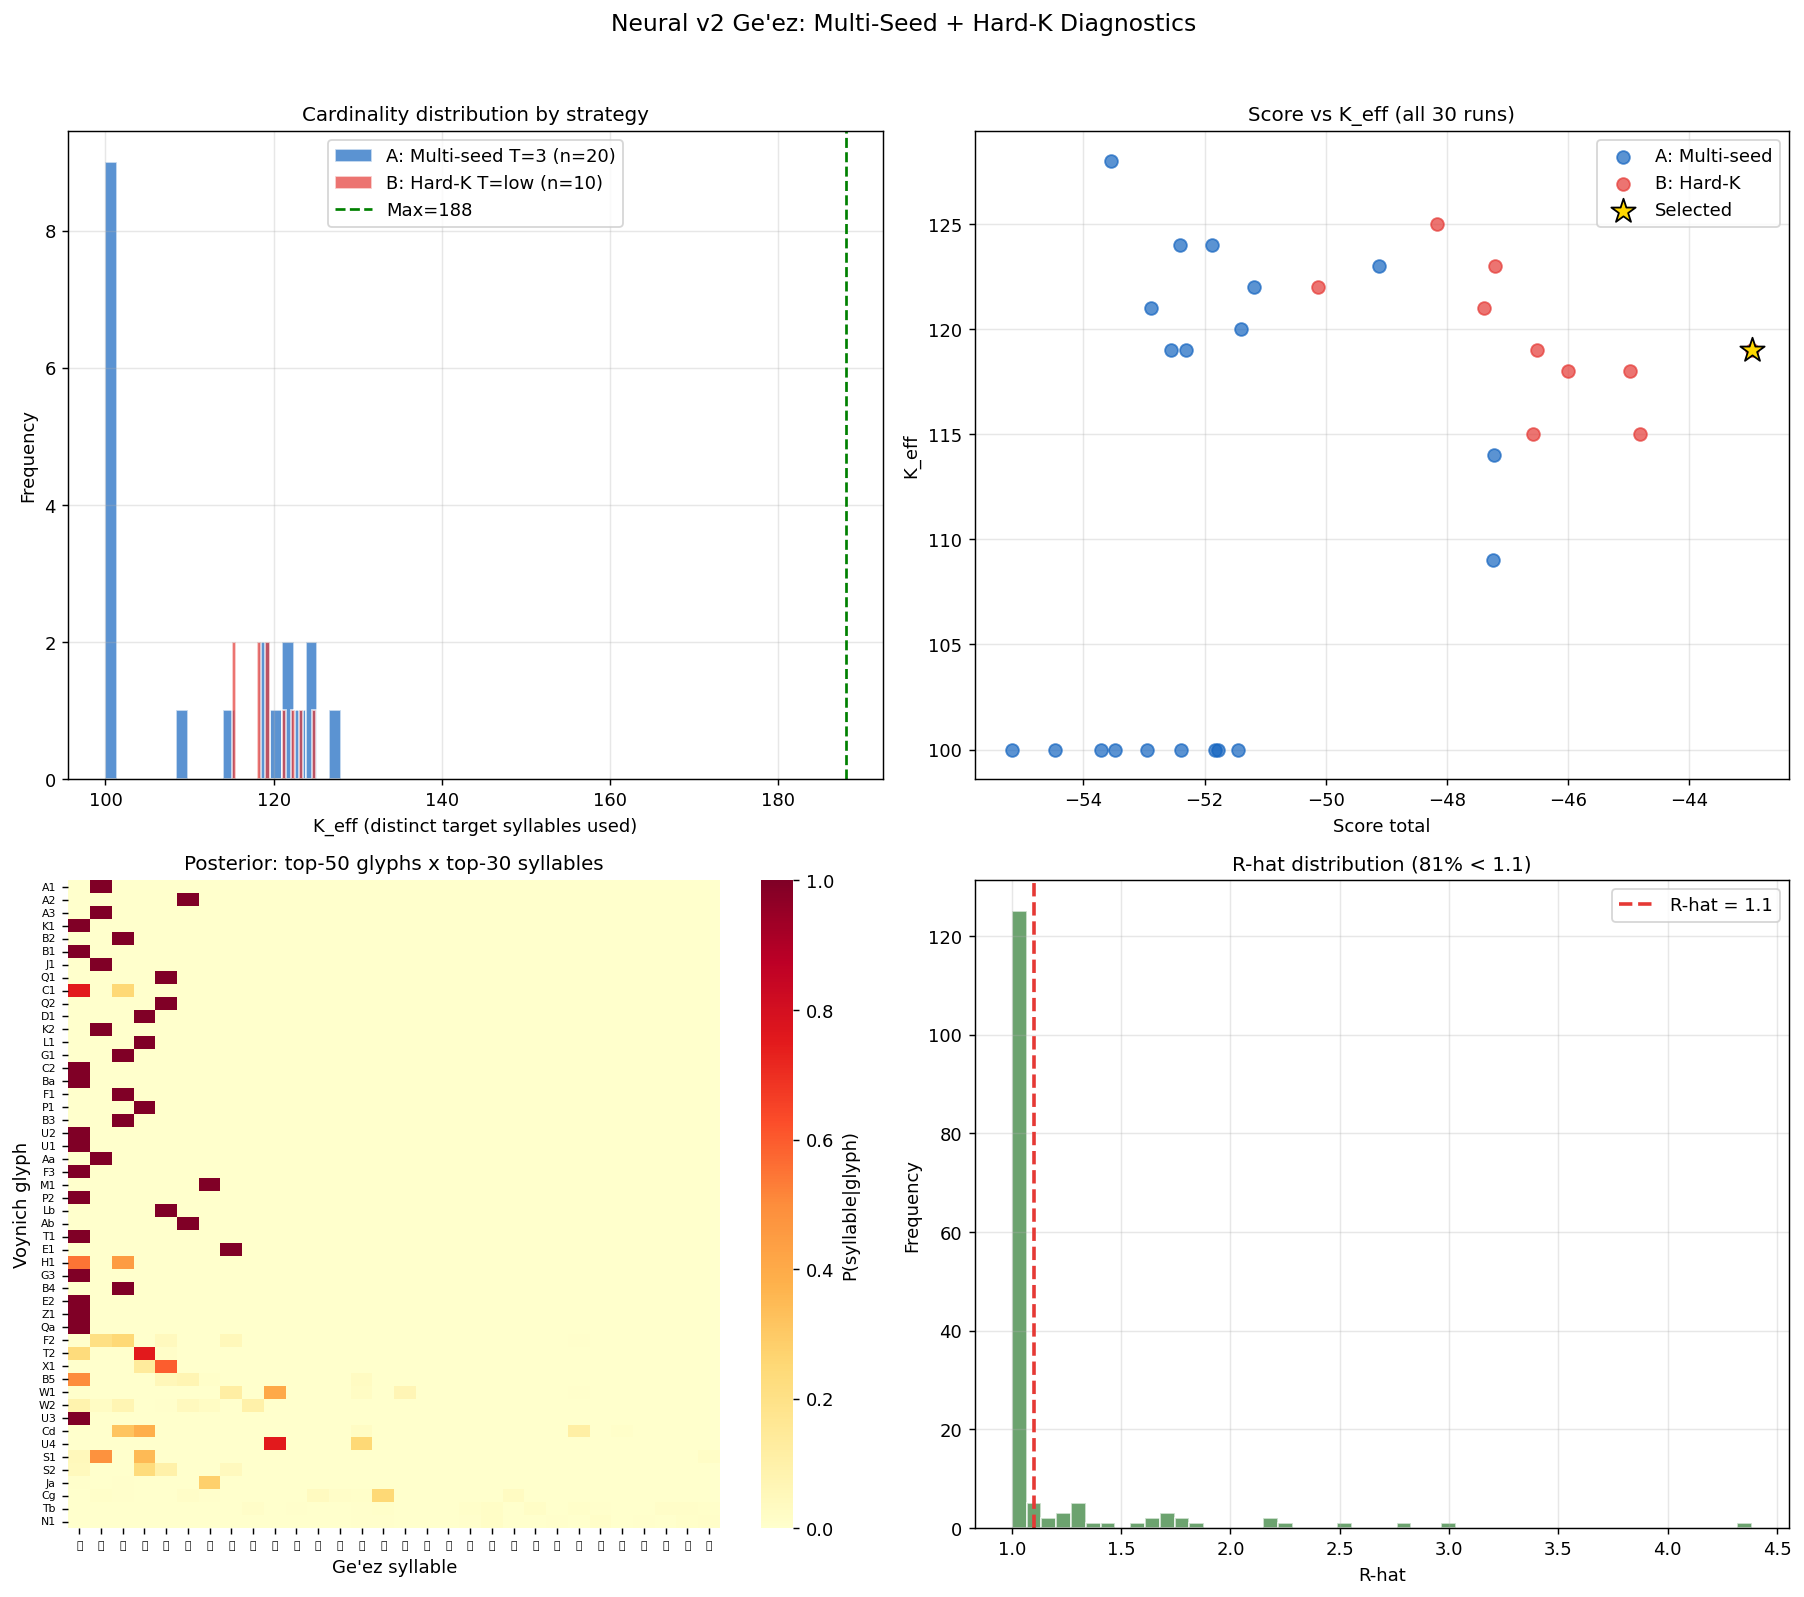

In [12]:
# -- Cell 12: Visualisations --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: Distribution of K_eff across seeds
ax = axes[0, 0]
keffs_a = [r['K_eff'] for r in multi_seed_results]
keffs_b = [r['K_eff'] for r in hard_k_results]
ax.hist(keffs_a, bins=20, alpha=0.7,
        color='#1565C0', label=f'A: Multi-seed T=3 (n={len(keffs_a)})', edgecolor='white')
ax.hist(keffs_b, bins=20, alpha=0.7,
        color='#E53935', label=f'B: Hard-K T=low (n={len(keffs_b)})', edgecolor='white')
ax.set_xlabel('K_eff (distinct target syllables used)')
ax.set_ylabel('Frequency')
ax.set_title('Cardinality distribution by strategy')
ax.axvline(len(target_chars_heb), color='green', linestyle='--', label=f'Max={len(target_chars_heb)}')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Score vs K_eff scatter (30 runs)
ax = axes[0, 1]
scores_a_vals = [r['score'] for r in multi_seed_results]
scores_b_vals = [r['score'] for r in hard_k_results]
ax.scatter(scores_a_vals, keffs_a, c='#1565C0', s=50, alpha=0.7, label='A: Multi-seed', zorder=3)
ax.scatter(scores_b_vals, keffs_b, c='#E53935', s=50, alpha=0.7, label='B: Hard-K', zorder=3)
ax.scatter([BEST['score']], [BEST['K_eff']], c='gold', s=200, marker='*',
           edgecolors='black', linewidths=1, zorder=5, label='Selected')
ax.set_xlabel('Score total')
ax.set_ylabel('K_eff')
ax.set_title('Score vs K_eff (all 30 runs)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Heatmap posterior (top-50 glyphs x top-30 syllables)
ax = axes[1, 0]
top50_glyphs = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:50]
# Find most-used target syllables in mapping
mapped_freq = Counter(mapping_v2.values())
top30_targets = [c for c, _ in mapped_freq.most_common(30)]
heatmap_data = np.zeros((len(top50_glyphs), len(top30_targets)))
for i, g in enumerate(top50_glyphs):
    if g in posterior_v2:
        for c, prob in posterior_v2[g].items():
            if c in top30_targets:
                j = top30_targets.index(c)
                heatmap_data[i, j] = prob

sns.heatmap(heatmap_data, ax=ax, cmap='YlOrRd',
            xticklabels=top30_targets, yticklabels=top50_glyphs,
            cbar_kws={'label': 'P(syllable|glyph)'})
ax.set_xlabel('Ge\'ez syllable')
ax.set_ylabel('Voynich glyph')
ax.set_title('Posterior: top-50 glyphs x top-30 syllables')
ax.tick_params(labelsize=6)

# Plot 4: R-hat distribution
ax = axes[1, 1]
rhat_finite = [v for v in rhat_vals if v < 5.0]
ax.hist(rhat_finite, bins=50, color='#2E7D32', alpha=0.7, edgecolor='white')
ax.axvline(1.1, color='#E53935', linestyle='--', linewidth=2, label='R-hat = 1.1')
ax.set_xlabel('R-hat')
ax.set_ylabel('Frequency')
ax.set_title(f'R-hat distribution ({pct_converged:.0f}% < 1.1)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Neural v2 Ge\'ez: Multi-Seed + Hard-K Diagnostics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [13]:
# -- Cell 13: Export results -> geez_resultados.json --------------------------

mapping_serializable = {g: c for g, c in mapping_v2.items()}

posterior_serializable = {}
for g, dist in posterior_v2.items():
    posterior_serializable[g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

resultados = {
    'metadata': {
        'notebook': '35_geez.ipynb',
        'model': 'neural_lstm_multi_seed_hard_k',
        'language': 'geez',
        'corpus': 'Classical Ge\'ez (Ethiopic) syllabary corpus',
        'description': 'Neural v2 pipeline against Ge\'ez -- first 1:1 ratio test (166 glyphs vs 188 syllables)',
    },
    'corpus_stats': {
        'n_words_full': len(hebrew_words_full),
        'n_words_sub': len(hebrew_words_sub),
        'n_chars': len(target_chars_heb),
        'sigma_A_ratio': round(len(VOCAB) / len(target_chars_heb), 3),
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
        'trained_on': f'full {len(hebrew_words_full):,} words',
    },
    'multi_seed_results': [{
        'seed': r['seed'], 'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in multi_seed_results],
    'hard_k_results': [{
        'T': float(r['T']), 'seed': int(r['seed']),
        'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']),
        'reject_pct': round(float(r['reject_pct']), 3),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in hard_k_results],
    'best_candidate': {
        'label': BEST['label'],
        'strategy': BEST['strategy'],
        'T': float(BEST['T']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': 'N/A',
        'cardinality_ratio': round(float(K_ratio), 3),
        'word_length_z': round(float(z_wl), 2),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL / {n_na} N/A',
    'mapping': mapping_serializable,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_v2.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'multi_seed_summary': {
        'n_seeds': N_SEEDS,
        'score_mean': round(float(np.mean([r['score'] for r in multi_seed_results])), 4),
        'score_std': round(float(np.std([r['score'] for r in multi_seed_results])), 4),
        'K_eff_mean': round(float(np.mean([r['K_eff'] for r in multi_seed_results])), 1),
        'K_eff_std': round(float(np.std([r['K_eff'] for r in multi_seed_results])), 1),
        'K_eff_max': int(max(r['K_eff'] for r in multi_seed_results)),
    },
    'hard_k_summary': {
        'K_min': K_MIN,
        'T_values': T_VALUES_LOW,
        'n_seeds_per_T': N_SEEDS_B,
        'K_eff_mean': round(float(np.mean([r['K_eff'] for r in hard_k_results])), 1),
        'K_eff_max': int(max(r['K_eff'] for r in hard_k_results)),
        'mean_reject_pct': round(float(np.mean([r['reject_pct'] for r in hard_k_results])), 3),
    },
}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

with open('geez_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to geez_resultados.json')
print(f'Keys: {list(resultados.keys())}')

print(f'\n-- Final summary --')
print(f'Model: Neural v2 (Multi-Seed + Hard-K) on Ge\'ez')
print(f'Best candidate: {BEST["label"]} (T={BEST["T"]})')
print(f'K_eff: {BEST["K_eff"]}')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL / {n_na} N/A')
print(f'R-hat convergence: {pct_converged:.0f}%')
print(f'|sigma|/|A| = {len(VOCAB)}/{len(target_chars_heb)} = {len(VOCAB)/len(target_chars_heb):.2f}')

Results exported to geez_resultados.json
Keys: ['metadata', 'corpus_stats', 'neural_lm', 'multi_seed_results', 'hard_k_results', 'best_candidate', 'mcmc_results', 'validation_scorecard', 'validation_details', 'scorecard_summary', 'mapping', 'posterior_top', 'rhat', 'multi_seed_summary', 'hard_k_summary']

-- Final summary --
Model: Neural v2 (Multi-Seed + Hard-K) on Ge'ez
Best candidate: B_T1.5_s3 (T=1.5)
K_eff: 119
Scorecard: 1 PASS / 0 MARGINAL / 3 FAIL / 1 N/A
R-hat convergence: 81%
|sigma|/|A| = 166/188 = 0.88


In [14]:
# -- Cell 14: 4-way comparison (Torah, Tibbonid, Judeo-Arabic, Ge'ez) ---------

print('='*80)
print('COMPARISON: Torah vs Tibbonid vs Judeo-Arabic vs Ge\'ez')
print('='*80)

# Load comparison results
def load_results(path, label):
    try:
        with open(path, 'r') as f:
            data = json.load(f)
        print(f'Loaded {path} ({label})')
        return data
    except FileNotFoundError:
        print(f'WARNING: {path} not found')
        return {}

torah = load_results('neural_v2_resultados.json', 'Torah')
tibbonid = load_results('tibbonid_resultados.json', 'Tibbonid')
judeo_arabic = load_results('judeo_arabic_resultados.json', 'Judeo-Arabic')

def get_metric(data, *keys, default='--'):
    obj = data
    for k in keys:
        if isinstance(obj, dict):
            obj = obj.get(k, None)
        else:
            return default
        if obj is None:
            return default
    return obj

def fmt(val, decimals=1):
    if val is None or val == '--':
        return '--'
    if isinstance(val, str):
        return val
    return f'{val:.{decimals}f}'

# Current Ge'ez metrics
geez_metrics = {
    'val_loss': best_val_loss,
    'ngram': pct_ngram,
    'roots': 'N/A',
    'collapse_z': mean_z,
    'rhat': pct_converged,
    'K_ratio': K_ratio,
    'score_mean': np.mean([r['score'] for r in multi_seed_results]),
    'K_eff_mean': np.mean([r['K_eff'] for r in multi_seed_results]),
    'scorecard': f'{n_pass}+/{n_marg}~/{n_fail}-/{n_na}na',
    'n_chars': len(target_chars_heb),
    'ratio': len(VOCAB) / len(target_chars_heb),
}

comparison_rows = [
    {
        'Metric': '|A| (target chars)',
        'Torah': fmt(get_metric(torah, 'corpus_stats', 'n_chars'), 0),
        'Tibbonid': fmt(get_metric(tibbonid, 'corpus_stats', 'n_chars'), 0),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'corpus_stats', 'n_chars'), 0),
        "Ge'ez": f'{geez_metrics["n_chars"]}',
    },
    {
        'Metric': '|sigma|/|A| ratio',
        'Torah': fmt(166 / max(int(get_metric(torah, 'corpus_stats', 'n_chars', default=27)), 1), 2),
        'Tibbonid': fmt(166 / max(int(get_metric(tibbonid, 'corpus_stats', 'n_chars', default=27)), 1), 2),
        'Judeo-Arabic': fmt(166 / max(int(get_metric(judeo_arabic, 'corpus_stats', 'n_chars', default=22)), 1), 2),
        "Ge'ez": f'{geez_metrics["ratio"]:.2f}',
    },
    {
        'Metric': 'LM val_loss',
        'Torah': fmt(get_metric(torah, 'neural_lm', 'best_val_loss'), 4),
        'Tibbonid': fmt(get_metric(tibbonid, 'neural_lm', 'best_val_loss'), 4),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'neural_lm', 'best_val_loss'), 4),
        "Ge'ez": f'{geez_metrics["val_loss"]:.4f}',
    },
    {
        'Metric': 'N-gram %ile',
        'Torah': fmt(get_metric(torah, 'validation_details', 'ngram_percentile'), 1),
        'Tibbonid': fmt(get_metric(tibbonid, 'validation_details', 'ngram_percentile'), 1),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'validation_details', 'ngram_percentile'), 1),
        "Ge'ez": f'{geez_metrics["ngram"]:.1f}',
    },
    {
        'Metric': 'Roots matched',
        'Torah': fmt(get_metric(torah, 'validation_details', 'roots_matched'), 0),
        'Tibbonid': fmt(get_metric(tibbonid, 'validation_details', 'roots_matched'), 0),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'validation_details', 'roots_matched'), 0),
        "Ge'ez": 'N/A',
    },
    {
        'Metric': 'Collapse z-score',
        'Torah': fmt(get_metric(torah, 'validation_details', 'collapse_mean_z'), 2),
        'Tibbonid': fmt(get_metric(tibbonid, 'validation_details', 'collapse_mean_z'), 2),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'validation_details', 'collapse_mean_z'), 2),
        "Ge'ez": f'{geez_metrics["collapse_z"]:.2f}',
    },
    {
        'Metric': 'R-hat < 1.1 %',
        'Torah': fmt(get_metric(torah, 'mcmc_results', 'pct_converged_rhat'), 1),
        'Tibbonid': fmt(get_metric(tibbonid, 'mcmc_results', 'pct_converged_rhat'), 1),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'mcmc_results', 'pct_converged_rhat'), 1),
        "Ge'ez": f'{geez_metrics["rhat"]:.1f}',
    },
    {
        'Metric': 'Cardinality ratio',
        'Torah': fmt(get_metric(torah, 'validation_details', 'cardinality_ratio'), 3),
        'Tibbonid': fmt(get_metric(tibbonid, 'validation_details', 'cardinality_ratio'), 3),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'validation_details', 'cardinality_ratio'), 3),
        "Ge'ez": f'{geez_metrics["K_ratio"]:.3f}',
    },
    {
        'Metric': 'Score mean (20s)',
        'Torah': fmt(get_metric(torah, 'multi_seed_summary', 'score_mean'), 4),
        'Tibbonid': fmt(get_metric(tibbonid, 'multi_seed_summary', 'score_mean'), 4),
        'Judeo-Arabic': fmt(get_metric(judeo_arabic, 'multi_seed_summary', 'score_mean'), 4),
        "Ge'ez": f'{geez_metrics["score_mean"]:.4f}',
    },
    {
        'Metric': 'Scorecard',
        'Torah': get_metric(torah, 'scorecard_summary', default='--'),
        'Tibbonid': get_metric(tibbonid, 'scorecard_summary', default='--'),
        'Judeo-Arabic': get_metric(judeo_arabic, 'scorecard_summary', default='--'),
        "Ge'ez": geez_metrics['scorecard'],
    },
]

df_comp = pd.DataFrame(comparison_rows)
print(df_comp.to_string(index=False))

print('\n-- Interpretation --')
print('This is the FIRST test with |sigma|/|A| ~ 1 (near-injective mapping possible).')
print('Previous tests (ratio ~6) suffered from LM dominance collapse.')
print('')
print('KEY QUESTIONS:')
print('1. Does the near-1:1 ratio produce higher K_eff (less collapse)?')
print('2. Does the n-gram percentile improve significantly?')
print('3. Is the mapping more structured (higher collapse z-scores)?')
print('')
print('If Ge\'ez performs BETTER than Hebrew despite no grammar anchors and no root')
print('validation, this would suggest the 166-glyph inventory is genuinely syllabic')
print('and the cardinality mismatch was the primary barrier all along.')
print('')
print('If Ge\'ez performs SIMILARLY or WORSE, this confirms the barrier is in the')
print('encoding mechanism itself, not the alphabet size ratio.')

COMPARISON: Torah vs Tibbonid vs Judeo-Arabic vs Ge'ez
Loaded neural_v2_resultados.json (Torah)
Loaded tibbonid_resultados.json (Tibbonid)
Loaded judeo_arabic_resultados.json (Judeo-Arabic)
            Metric                        Torah                     Tibbonid                 Judeo-Arabic        Ge'ez
|A| (target chars)                           --                           27                           22          188
 |sigma|/|A| ratio                         6.15                         6.15                         7.55         0.88
       LM val_loss                       2.0039                       2.1071                       1.9753       2.0166
       N-gram %ile                         68.0                         13.0                         12.0          0.0
     Roots matched                            3                            3                            1          N/A
  Collapse z-score                        -0.94                        -0.90                    